# **4. Product Purchasing Behaviour Analysis**

### **Introduction**

This analysis will focus on the Customer Personality Analysis dataset, which provides detailed insights into customer demographics, financial backgrounds, family structures, and purchasing patterns to support marketing analysis. The dataset contains information such as age, education, marital status, income, and the number of children at home. It also includes data on customer spending across different product categories, purchase frequency, website engagement, and responses to marketing campaigns. 


### **Project Objective :**

Our study will focus on the relationship between aspects of customers' perosnality & their purchasing behaviour:

__1. Impact of Family Structure on Product Purchases.__

__2. Impact of Education Level on Purchase Channels.__

__3. Relationship Between Income and Purchasing Behaviour.__

---


#### **Customer Personality Dataset Description:**

The Customer Personality Analysis dataset is a Kaggle dataset designed for customer segmentation, containing demographic details, spending habits, and product preferences of retail customers.


### **Feature description:**

__Customer information__: ID

__Demographics__: Age, Education

__Financial data__: Income

__Family structure__: Marital Status, Kidhome, Teenhome

__Spending behavior__: Wine, Fruits, Meat, Fish, Sweets, Gold

__Purchasing behavior__: Web, Store, Catalog purchases

__Marketing behavior/Promotion__: Num Deal purchases, Campaign acceptance, responses

__Engagement__: Recency, website visits, complaints

__Enrollement__: Dt_customer


**This dataset represents the customers profile and behaviour across multiple years, where each row corresponds to one customer. It includes demographic details, family composition, income, purchasing behaviour and product spending.**

---


### **Table of Contents**

__1. Setup & intialization__
- 1.1. Importing necessary libraries
- 1.2. Loading the dataset

__2. Exploratory data analysis(EDA)__
- 2.1. Impact of Family Structure on Product Purchases
- 2.2. Impact of Education Level on Purchase Channels.
- 2.3. Relationship Between Income and Purchasing Behaviour.

__3. Conclusion__

---


## **Step 1. Setup & Initalization**

**1.1. Importing necessary libraries**


In [1]:
# import libraries
import sys
sys.path.append('..')
from src.utilis import *


**1.2. Loading the dataset**

In [2]:
# Define paths to read files
parent_path = Path.cwd().parent
data_path = parent_path.joinpath('data', 'raw')

files = []
display_md("**Original Dataset :**")
for file in data_path.rglob('*.csv'):
    files.append(file)
    print(files.index(file), ' ', file.name)

display_md("**Loading Raw Dataset...**")

try:
    customer_org = pd.read_csv(files[0], sep='\t')
    
    # standardize the column names
    customer_org.columns = customer_org.columns.str.strip().str.replace(" ", "_").str.replace(".", "_")

    # take a copy of original dataframe
    customer_data = customer_org.copy()
    
    # Conversion of 'Dt_Customer' into datetime
    customer_data['Dt_Customer'] = pd.to_datetime(customer_data['Dt_Customer'], format='%d-%m-%Y')
    display_md(f"**Dataset Shape : {customer_data.shape}**")
    display_md(f"**Number of duplicate rows in dataset : {customer_data.duplicated().sum()}**")
    
except Exception as e:
    print(f"Error raised while loading file : {e}")



**Original Dataset :**

0   marketing_campaign.csv


**Loading Raw Dataset...**

**Dataset Shape : (2240, 29)**

**Number of duplicate rows in dataset : 0**

## **2. Exploratory data analysis (EDA)**

Let's explore the key questions outlined in the project objectives.


### **`Q1: Impact of family structure on product purchasing behaviour`**

(i) In this analysis, we aim to understand how different marital statuses (Single, Together, Married, and Divorced) influence customers' spending patterns across three product categories: wine, meat, and gold. To explore these relationships, we will use boxplots to visualize and compare the spending distributions for each marital status using the variables __Marital_Status, MntWines, MntMeatProducts, and MntGoldProds__.

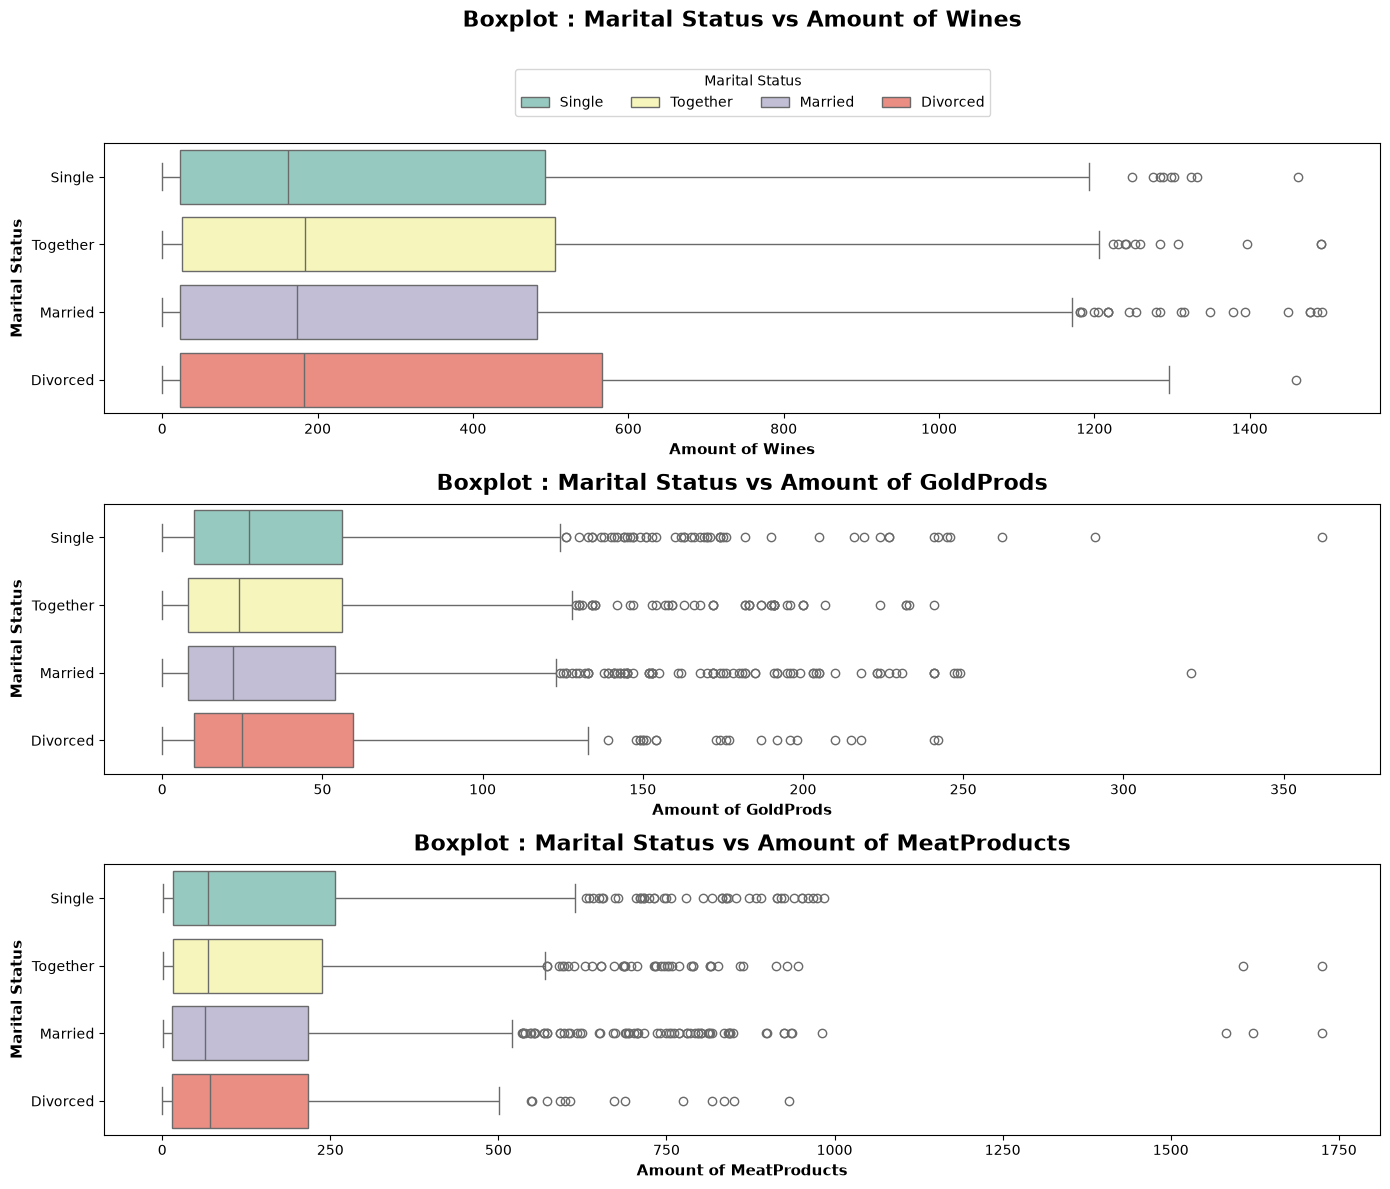

In [43]:
family_df = customer_data[['Marital_Status', 'MntWines', 'MntGoldProds', 'MntMeatProducts']].copy()

# Group marital status into 4 main categories
family_df['Marital_Status'] = family_df['Marital_Status'].replace({
    'Absurd': 'Single',
    'YOLO': 'Single',
    'Alone': 'Single',
    'Widow': 'Single'
})

fig, ax = plt.subplots(3, 1, figsize=(14, 12))
ax = ax.flatten()

for i, col in enumerate(['MntWines', 'MntGoldProds', 'MntMeatProducts']):
    sns.boxplot(
        data=family_df,
        y='Marital_Status', x = col,
        hue='Marital_Status', palette='Set3',
        legend=True,
        ax=ax[i]
    )
    if i == 0:
        ax[i].set_title(f"Boxplot : Marital Status vs Amount of {col[3:]}", fontsize=16, fontweight='bold', y=1.4)
    else:
        ax[i].set_title(f"Boxplot : Marital Status vs Amount of {col[3:]}", fontsize=16, fontweight='bold', y=1.02)
    ax[i].set_ylabel("Marital Status", fontsize=11, fontweight='bold')
    ax[i].set_xlabel(f"Amount of {col[3:]}", fontsize=11, fontweight='bold')
    if i == 0:
        ax[i].legend(title='Marital Status', bbox_to_anchor=(0.7, 1.3), ncol=4)
    else:
        ax[i].get_legend().remove()

plt.tight_layout()
plt.subplots_adjust(wspace=0.04)
plt.show()



**Analysis**

The above boxplots illustrate how different marital statuses may influence customers' spending patterns across selected product categories. We chose Wine, Meat, and Gold because these categories are likely to show variations in purchasing behavior based on marital status.

From the first set of boxplots, which represents spending on Wine, we observe that customers in the __Together__ category have the highest median expenditure, followed by **Divorced, Married, & Single**. Additionally, the Divorced category exhibits the widest range of spending, indicating greater variability in wine purchases among these customers.

The second set of boxplots, which illustrates spending on Gold, indicates that customers in the __Single & Divorced__ categories have the highest median spending. Similar to the Wine spending analysis, the Divorced category exhibits the widest range, suggesting greater variability in spending. In comparison, the Single and Married categories contain more outliers, indicating that some customers in these groups spend considerably more on Gold than others. Furthermore, the IQR appears relatively consistent across all marital-status categories, suggesting that the middle 50% of customers have fairly similar spending distributions.

The third set of boxplots, which represents spending on Meat, shows that customers in the __Divorced__ category have the highest median expenditure, followed by __Together, Single, & Married__. The Single category exhibits the widest range of spending, indicating greater variability in meat purchases. In contrast, the Divorced category has a narrower distribution, suggesting more consistent spending patterns among these customers. However, spending variability alone does not necessarily indicate differences in income stability.

Overall, the results suggest that customers in the __Divorced__ & __Together__ categories tend to have higher spending levels across the selected product categories compared to those in the __Married__ and __Single__ categories, as per below data.


In [50]:
data = family_df.groupby(['Marital_Status']).median()
data['Total_consumption'] = data.sum(axis='columns')
data = data.sort_values(by='Total_consumption', ascending =False)
data

,MntWines,MntGoldProds,MntMeatProducts,Total_consumption
Marital_Status,,,,
Divorced,182.50,25.00,71.50,279.00
Together,183.50,24.00,68.00,275.50
Married,173.00,22.00,64.00,259.00
Single,162.00,27.00,68.00,257.00
